In [1]:
import torch
from torchvision import datasets
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_device(device)
print("Device:", device)

Device: cuda


In [2]:
def load_mnist(root="./data", val_size=10_000, seed=42):
    """Return {'train', 'val', 'test'} -> (X, y), plus the class count.

    X is float32, flattened to (N, 784) and  normalized to [0, 1]
    """
    train_dataset = datasets.MNIST(root=root, train=True, download=True)
    test_dataset = datasets.MNIST(root=root, train=False, download=True)

    def as_tensors(dataset):
        X = dataset.data.flatten(start_dim=1).float() / 255.0
        y = dataset.targets
        return X.to(device), y.to(device)

    X, y = as_tensors(train_dataset)
    Xtest, Ytest = as_tensors(test_dataset)

    generator = torch.Generator(device="cpu").manual_seed(seed)
    indices = torch.randperm(len(X), generator=generator, device="cpu").to(device)
    split_at = len(X) - val_size
    train_idx, val_idx = indices[:split_at], indices[split_at:]

    splits = {
        "train": (X[train_idx], y[train_idx]),
        "val": (X[val_idx], y[val_idx]),
        "test": (Xtest, Ytest),
    }
    return splits, len(train_dataset.classes)


In [3]:
splits, n_out = load_mnist()
for name, (X, y) in splits.items():
    print(f"{name}: X={tuple(X.shape)}, y={tuple(y.shape)}, device={X.device}")

train: X=(50000, 784), y=(50000,), device=cuda:0
val: X=(10000, 784), y=(10000,), device=cuda:0
test: X=(10000, 784), y=(10000,), device=cuda:0


In [4]:
class Linear:
    """Apply a learned affine transformation to the final feature dimension."""

    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        out = x @ self.weight
        if self.bias is not None:
            out = out + self.bias
        return out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
    """Normalize 2D/3D features; track statistics for evaluation."""

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3:
                dim = (0, 1)
            else:
                raise ValueError("BatchNorm1d expects a 2D or 3D tensor")
            mean = x.mean(dim, keepdim=True)
            var = x.var(dim, keepdim=True)
        else:
            mean = self.running_mean
            var = self.running_var

        out = self.gamma * ((x - mean) / torch.sqrt(var + self.eps)) + self.beta
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * mean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * var
        return out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:
    def __call__(self, x):
        return torch.tanh(x)

    def parameters(self):
        return []


class Sequential:
    """Run layers in order; collect parameters and manage nested train/eval mode."""

    def __init__(self, layers):
        self.layers = layers
        self.training = True

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def set_training(self, mode):
        self.training = mode
        for layer in self.layers:
            if hasattr(layer, "set_training"):
                layer.set_training(mode)
            elif hasattr(layer, "training"):
                layer.training = mode


class ResidualBlock:
    """Apply x + F(x), preserving the (batch_size, fan_in) shape."""

    def __init__(self, fan_in, expansion=2):
        self.layers = Sequential([
            Linear(fan_in, fan_in * expansion),
            Tanh(),
            Linear(fan_in * expansion, fan_in),
        ])

    def __call__(self, x):
        return x + self.layers(x)

    def parameters(self):
        return self.layers.parameters()

    def set_training(self, mode):
        self.layers.set_training(mode)

In [6]:
def build_model(n_in, n_h, n_out, n_blocks=3, expansion=2):
    """Build a residual MLP mapping (B, n_in) to (B, n_out) logits."""
    model = Sequential([
        Linear(n_in, n_h, bias=False),
        BatchNorm1d(n_h),
        Tanh(),
        *[ResidualBlock(n_h, expansion) for _ in range(n_blocks)],
        Linear(n_h, n_out),
    ])
    with torch.no_grad():
        model.layers[-1].weight *= 0.1
    return model

In [7]:
n_in = splits["train"][0].shape[1]
n_h = 128
model = build_model(n_in, n_h, n_out, n_blocks=3)

print("Parameter count:", sum(p.numel() for p in model.parameters()))

Parameter count: 299658


In [8]:
def train_model(model, train_data, *, max_steps=6000, batch_size=256,
                learning_rate=0.01, decay_step=4000, log_every=200):
    """Train with random minibatches and SGD"""
    Xtr, Ytr = train_data
    parameters = model.parameters()
    for p in parameters:
        p.requires_grad_(True)
    model.set_training(True)

    losses = []
    for step in range(max_steps):
        ix = torch.randint(0, len(Xtr), (batch_size,), device=Xtr.device)
        Xb, Yb = Xtr[ix], Ytr[ix]

        logits = model(Xb)
        loss = F.cross_entropy(logits, Yb)

        for p in parameters:
            p.grad = None
        loss.backward()

        lr = learning_rate if step < decay_step else learning_rate * 0.1
        with torch.no_grad():
            for p in parameters:
                p -= lr * p.grad

        losses.append(loss.detach())
        if log_every and step % log_every == 0:
            print(f"{step:5d}/{max_steps}: {loss.item():.4f}")

    return torch.stack(losses).cpu().numpy()

losses = train_model(model, splits["train"])

    0/6000: 2.2954
  200/6000: 0.4464
  400/6000: 0.4518
  600/6000: 0.3127
  800/6000: 0.3613
 1000/6000: 0.2411
 1200/6000: 0.2336
 1400/6000: 0.2678
 1600/6000: 0.2302
 1800/6000: 0.2152
 2000/6000: 0.3005
 2200/6000: 0.1637
 2400/6000: 0.1807
 2600/6000: 0.1659
 2800/6000: 0.1613
 3000/6000: 0.1452
 3200/6000: 0.1316
 3400/6000: 0.1434
 3600/6000: 0.1181
 3800/6000: 0.1090
 4000/6000: 0.1023
 4200/6000: 0.0871
 4400/6000: 0.1018
 4600/6000: 0.1949
 4800/6000: 0.0879
 5000/6000: 0.0882
 5200/6000: 0.0551
 5400/6000: 0.0944
 5600/6000: 0.1583
 5800/6000: 0.1329


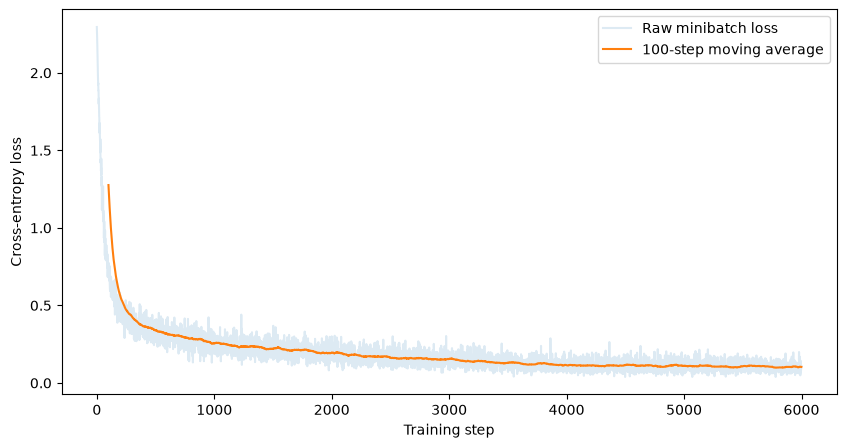

In [9]:
window = 100
smoothed = pd.Series(losses).rolling(window=window).mean()

plt.figure(figsize=(10, 5))
plt.plot(losses, alpha=0.15, label="Raw minibatch loss")
plt.plot(smoothed, label=f"{window}-step moving average")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.show()

In [10]:
@torch.no_grad()
def evaluate(model, data, batch_size=1024):
    """Return mean cross-entropy and accuracy without changing model mode."""
    X, Y = data
    was_training = model.training
    model.set_training(False)

    try:
        loss_sum = 0.0
        correct = 0
        for start in range(0, len(X), batch_size):
            xb = X[start:start + batch_size]
            yb = Y[start:start + batch_size]
            logits = model(xb)
            loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
            correct += (logits.argmax(dim=1) == yb).sum().item()

        return {"loss": loss_sum / len(X), "accuracy": correct / len(X)}
    finally:
        model.set_training(was_training)


In [11]:
for split in ("train", "val"):
    metrics = evaluate(model, splits[split])
    print(f"{split}: loss={metrics['loss']:.4f}, accuracy={metrics['accuracy']:.4f}")

train: loss=0.1027, accuracy=0.9717
val: loss=0.1674, accuracy=0.9491
